In [99]:
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.stats.multitest as sm 
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer


In [51]:
# Load and tidy data

df = pd.read_csv('../../raw_data/Glycosphingolipid_analysis/Deep-surface_GSLs.csv')
df['patient_id'] = list(df['id'].str.split('_', expand = True)[1].str.split('Deep', expand = True)[0].str.split('Surface', expand = True)[0])
df['type'] = np.where(df['id'].str.contains('Deep', case=False, na=False), 'Deep', 'Surface')
categories = ['2.16', 'GA2', '2.67', 'Gb3', 'GM3', '3.23', 'GM2','3.57', '3.61', 'GA1', '4.03', 'GM1a', 'GD3', 'GM1b', 'GD2', 'GD1a','5.24', '5.33', '5.45', 'GD1b', '5.99', 'GT1b', '6.84', '6.99', 'GQ1b','8.07']
deep = df[df['type']=='Deep']
deep.columns = [col + '_deep' for col in deep.columns]
deep.rename(columns = {'id_deep':'id','group_deep':'group','patient_id_deep':'patient_id','type_deep':'type'}, inplace = True)
surface = df[df['type']=='Surface']
surface.columns = [col + '_surface' for col in surface.columns]
surface.drop(columns = ['group_surface', 'id_surface', 'type_surface', 'id_surface'], inplace = True)
surface.rename(columns = {'patient_id_surface':'patient_id'}, inplace = True)
surface

# Merge surface and deep data to facilitate pairwise comparison
paired = deep.merge(surface, left_on = 'patient_id', right_on = 'patient_id', how = 'inner')
PD_paired = paired[paired['group']=='PD']
Ctrl_paired = paired[paired['group']=='Control']
paired

/tmp/ipykernel_428120/1561729538.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  deep.rename(columns = {'id_deep':'id','group_deep':'group','patient_id_deep':'patient_id','type_deep':'type'}, inplace = True)
/tmp/ipykernel_428120/1561729538.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  surface.drop(columns = ['group_surface', 'id_surface', 'type_surface', 'id_surface'], inplace = True)
/tmp/ipykernel_428120/1561729538.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/

,id,group,2.16_deep,GA2_deep,2.67_deep,Gb3_deep,GM3_deep,3.23_deep,GM2_deep,3.57_deep,...,5.24_surface,5.33_surface,5.45_surface,GD1b_surface,5.99_surface,GT1b_surface,6.84_surface,6.99_surface,GQ1b_surface,8.07_surface
0,1_P14/20Deep,Control,0.000201,0.009126,NaN,0.002207,0.025647,0.000467,0.030267,0.001530,...,0.005613,0.005787,0.004466,0.470396,0.018230,0.268218,0.002209,0.002750,0.017034,0.000667
1,1_P23/21Deep,Control,NaN,0.008130,NaN,NaN,0.020995,NaN,0.058361,NaN,...,0.004686,0.004885,0.003053,0.337870,0.013257,0.185949,0.001257,0.001399,0.009268,NaN
2,1_P48/15Deep,Control,0.000243,0.001372,0.000648,0.002009,0.025151,NaN,0.034039,NaN,...,0.005578,0.006268,0.003622,0.541131,0.019742,0.299415,0.001590,NaN,0.016234,NaN
3,1_P57/18Deep,Control,0.000579,0.002921,0.000864,0.002586,0.026219,NaN,0.032225,NaN,...,0.013412,NaN,0.003682,0.373070,0.017058,0.222300,0.001217,0.001750,0.011182,NaN
4,1_P58/10Deep,Control,NaN,0.017903,NaN,NaN,0.016756,NaN,0.043032,NaN,...,0.013513,NaN,0.003769,0.443720,0.017469,0.260303,0.001442,0.001480,0.012349,NaN
5,2_P13/21Deep,PD,0.000242,0.000013,0.000285,0.002157,0.024764,0.000319,0.019723,NaN,...,0.006135,NaN,0.001892,0.196996,0.009847,0.131783,0.000554,0.000402,0.006072,NaN
6,2_P16/16Deep,PD,0.000145,0.000196,0.000280,0.001839,0.026715,0.000370,0.033038,NaN,...,0.003572,0.003744,0.002263,0.265460,0.010537,0.140739,0.000761,0.000405,0.020181,NaN
7,2_P19/20Deep,PD,0.000454,0.022506,NaN,0.003081,0.029177,NaN,0.064629,NaN,...,0.011952,NaN,0.003841,0.446273,0.019441,0.294677,0.001779,0.001391,0.017323,NaN
8,2_P26/18Deep,PD,0.000214,0.002920,0.000317,0.002039,0.036798,0.000468,0.053034,0.001127,...,0.012776,NaN,0.003786,0.374159,0.016586,0.229599,0.001045,0.001244,0.011178,NaN
9,2_P65/19Deep,PD,NaN,NaN,NaN,NaN,0.019721,NaN,0.028175,NaN,...,0.013063,NaN,0.004555,0.485066,0.019890,0.291512,0.001681,0.002463,0.016446,0.000210


## Independent t-test

In [109]:
# Perform paired analyses

list_tests = []
for comp in categories:
    paired_filtered = PD_paired[[col for col in PD_paired.columns if comp in col]]
    paired_filtered.dropna(inplace = True)
    #print(comp)
    #print(np.shape(paired_filtered))
    if np.shape(paired_filtered)[0]<3:
        #print(f"Skipping {comp}: only {paired_filtered.shape[0]} samples")
        continue
    else:
        res = stats.ttest_ind(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        #res = wilcoxon(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        list_tests.append(comp)
        if comp == categories[0]:
            total_res = pd.DataFrame(res).T
        else:
            total_res = pd.concat([total_res, pd.DataFrame(res).T], axis = 0)


total_res.rename(columns = {0:'statistic',1:'pval'}, inplace = True)
total_res.index = list_tests
total_res.dropna(inplace = True)
total_res['padj'] = sm.fdrcorrection(list(total_res['pval']), alpha=0.05, method='indep', is_sorted=False)[1]

sig = total_res[total_res['pval']<0.05]

/tmp/ipykernel_428120/3715682148.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/3715682148.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/3715682148.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/3715682148.py:6: SettingWithCopyWarning: 
A v

In [110]:
sig

,statistic,pval,padj
Gb3,-2.730465,0.034165,0.649134


In [111]:
# Perform paired analyses
del(paired_filtered)
list_tests = []
for comp in categories:
    paired_filtered = Ctrl_paired[[col for col in Ctrl_paired.columns if comp in col]]
    paired_filtered.dropna(inplace = True)
    #print(comp)
    #print(np.shape(paired_filtered))
    if np.shape(paired_filtered)[0]<3:
        #print(f"Skipping {comp}: only {paired_filtered.shape[0]} samples")
        continue
    else:
        res = stats.ttest_ind(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        #res = wilcoxon(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        list_tests.append(comp)
        if comp == categories[1]:
            total_res = pd.DataFrame(res).T
        else:
            total_res = pd.concat([total_res, pd.DataFrame(res).T], axis = 0)


total_res.rename(columns = {0:'statistic',1:'pval'}, inplace = True)
total_res.index = list_tests
total_res.dropna(inplace = True)
total_res['padj'] = sm.fdrcorrection(list(total_res['pval']), alpha=0.05, method='indep', is_sorted=False)[1]

sig = total_res[total_res['pval']<0.05]

/tmp/ipykernel_428120/1252779616.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/1252779616.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/1252779616.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/1252779616.py:6: SettingWithCopyWarning: 
A v

In [112]:
sig

,statistic,pval,padj


## Paired t-test

In [134]:
# Perform paired analyses

list_tests = []
for comp in categories:
    paired_filtered = PD_paired[[col for col in PD_paired.columns if comp in col]]
    paired_filtered.dropna(inplace = True)
    #print(comp)
    #print(np.shape(paired_filtered))
    if np.shape(paired_filtered)[0]<3:
        #print(f"Skipping {comp}: only {paired_filtered.shape[0]} samples")
        continue
    else:
        res = stats.ttest_rel(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        #res = wilcoxon(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        list_tests.append(comp)
        if comp == categories[0]:
            total_res = pd.DataFrame(res).T
        else:
            total_res = pd.concat([total_res, pd.DataFrame(res).T], axis = 0)


total_res.rename(columns = {0:'statistic',1:'pval'}, inplace = True)
total_res.index = list_tests
total_res.dropna(inplace = True)
total_res['padj'] = sm.fdrcorrection(list(total_res['pval']), alpha=0.05, method='indep', is_sorted=False)[1]

sig = total_res[total_res['pval']<0.05]

/tmp/ipykernel_428120/440169113.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/440169113.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/440169113.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/440169113.py:6: SettingWithCopyWarning: 
A value

In [114]:
sig

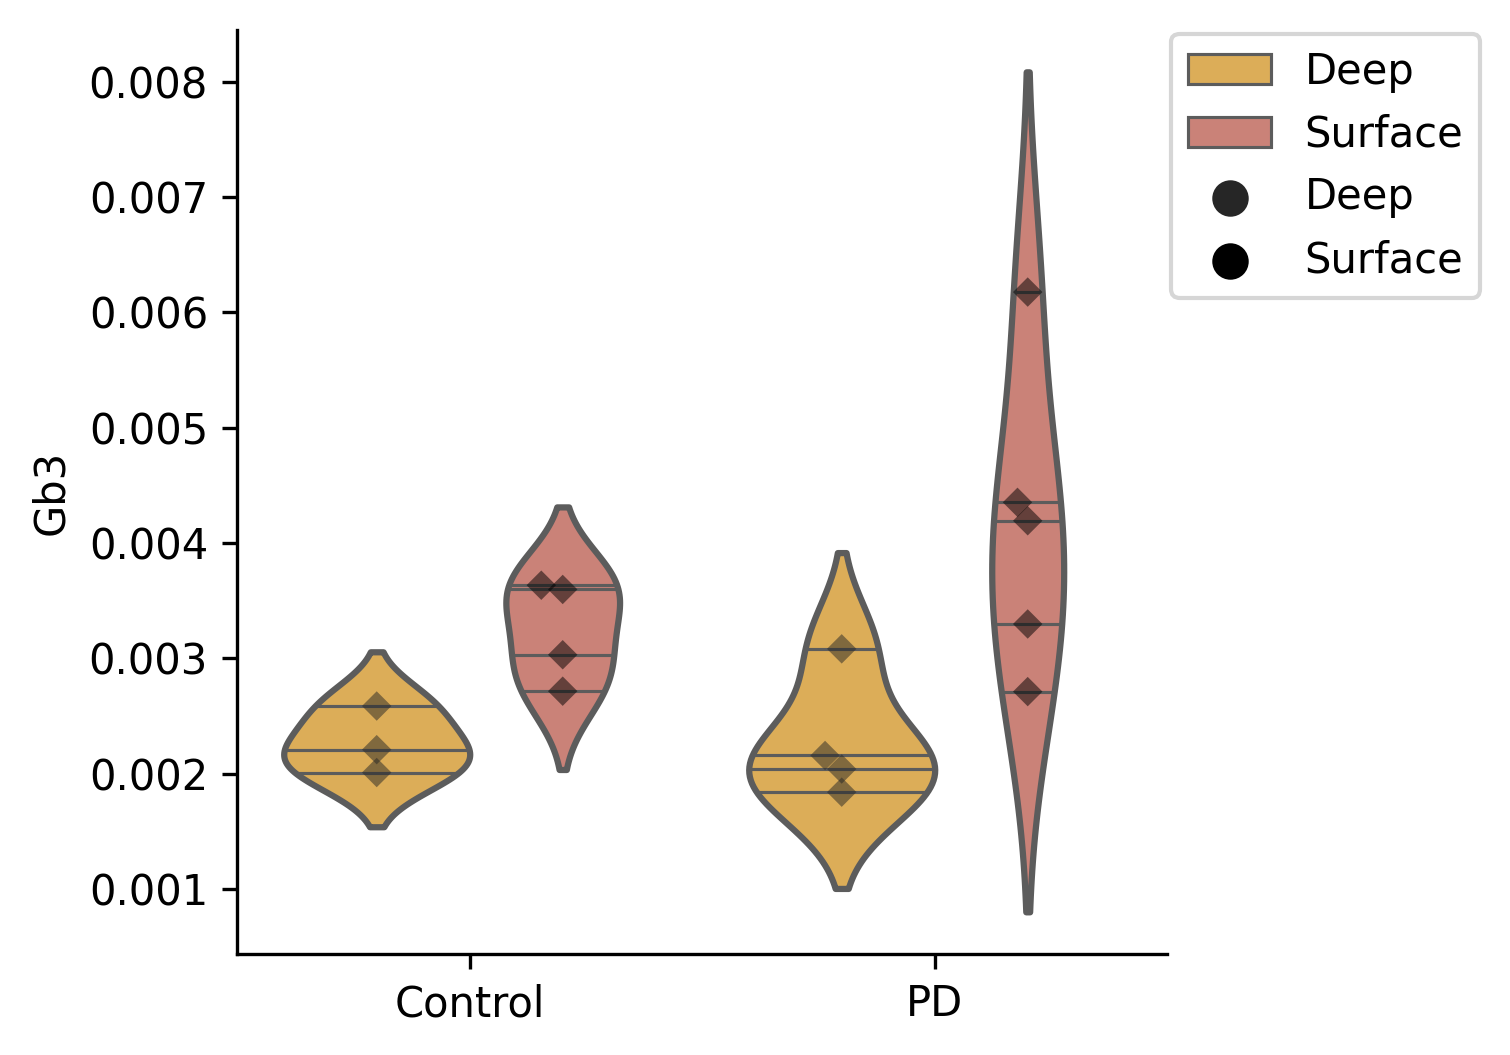

In [169]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(4, 4), dpi=300)

for cat in list(sig.index):
    ax = sns.violinplot(x = df["group"], y = df[cat], hue = df["type"], inner="stick",  palette={"Surface": "#D7786B", "Deep":"#F2B342"})
    sns.despine(top = True, right = True)
    sns.swarmplot(x = df["group"], y = df[cat], hue = df["type"], dodge=True, color = 'black', marker="D", alpha=.5)
    plt.legend(bbox_to_anchor=(1, 1), loc='upper left', borderaxespad=0.1)
    ax.set_xlabel('')
    plt.savefig('../../plots/09_validation_lipids/%s_violin_significant.png' % cat, bbox_inches = 'tight', dpi = 300)
    plt.savefig('../../plots/09_validation_lipids/%s_violin_significant.pdf' % cat, bbox_inches = 'tight', dpi = 300)
    plt.show()

In [115]:
# Perform paired analyses
#del(total_res)
list_tests = []
for comp in categories:
    paired_filtered = Ctrl_paired[[col for col in Ctrl_paired.columns if comp in col]]
    paired_filtered.dropna(inplace = True)
    #print(comp)
    #print(np.shape(paired_filtered))
    if np.shape(paired_filtered)[0]<3:
        #print(f"Skipping {comp}: only {paired_filtered.shape[0]} samples")
        continue
    else:
        res = stats.ttest_rel(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        #res = wilcoxon(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        list_tests.append(comp)
        if comp == categories[1]:
            total_res = pd.DataFrame(res).T
        else:
            total_res = pd.concat([total_res, pd.DataFrame(res).T], axis = 0)


total_res.rename(columns = {0:'statistic',1:'pval'}, inplace = True)
total_res.index = list_tests
total_res.dropna(inplace = True)
total_res['padj'] = sm.fdrcorrection(list(total_res['pval']), alpha=0.05, method='indep', is_sorted=False)[1]

sig = total_res[total_res['pval']<0.05]

import seaborn as sns
import matplotlib.pyplot as plt

for cat in list(sig.index):
    sns.violinplot(x = df["group"], y = df[cat], hue = df["type"], split = True, inner="stick")
    #sns.swarmplot(x = df["group"], y = df[cat], hue = df["type"])
    plt.show()

/tmp/ipykernel_428120/1496645960.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/1496645960.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/1496645960.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/1496645960.py:6: SettingWithCopyWarning: 
A v

In [116]:
sig

,statistic,pval,padj


## Paired t-test with imputation

In [117]:
numeric_df = PD_paired.select_dtypes(include='number')

# ⚙️ Initialize the imputer (mean strategy by default)
imputer = SimpleImputer(strategy='median')

# 🧹 Fit and transform numeric data
imputed_array = imputer.fit_transform(numeric_df)

imputed_pd_df = pd.DataFrame(
    imputed_array,
    columns=imputer.get_feature_names_out(numeric_df.columns)
)

In [127]:
from sklearn.impute import KNNImputer

numeric_df = PD_paired.select_dtypes(include='number')

# 🤝 Initialize the KNN imputer
imputer = KNNImputer(n_neighbors=3)

# 💡 Fit and transform the numeric data
imputed_array = imputer.fit_transform(numeric_df)

# 🧾 Reconstruct DataFrame using retained feature names
imputed_df = pd.DataFrame(imputed_array, columns=imputer.get_feature_names_out(numeric_df.columns))

print(imputed_df)


   2.16_deep  GA2_deep  2.67_deep  Gb3_deep  GM3_deep  3.23_deep  GM2_deep  \
0   0.000242  0.000013   0.000285  0.002157  0.024764   0.000319  0.019723   
1   0.000145  0.000196   0.000280  0.001839  0.026715   0.000370  0.033038   
2   0.000454  0.022506   0.000294  0.003081  0.029177   0.000386  0.064629   
3   0.000214  0.002920   0.000317  0.002039  0.036798   0.000468  0.053034   
4   0.000271  0.008541   0.000294  0.002320  0.019721   0.000386  0.028175   

   3.57_deep  3.61_deep  GA1_deep  ...  5.24_surface  5.33_surface  \
0   0.001127   0.000643  0.015683  ...      0.006135      0.003744   
1   0.001127   0.001041  0.020335  ...      0.003572      0.003744   
2   0.001127   0.000653  0.017716  ...      0.011952      0.003744   
3   0.001127   0.000633  0.019807  ...      0.012776      0.003744   
4   0.001127   0.000775  0.014766  ...      0.013063      0.003744   

   5.45_surface  GD1b_surface  5.99_surface  GT1b_surface  6.84_surface  \
0      0.001892      0.196996      

In [128]:
# Perform paired analyses

list_tests = []
for comp in categories:
    paired_filtered = imputed_pd_df[[col for col in imputed_pd_df.columns if comp in col]]
    paired_filtered.dropna(inplace = True)
    #print(comp)
    #print(np.shape(paired_filtered))
    if np.shape(paired_filtered)[0]<3:
        #print(f"Skipping {comp}: only {paired_filtered.shape[0]} samples")
        continue
    else:
        res = stats.ttest_rel(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        #res = wilcoxon(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        list_tests.append(comp)
        if comp == categories[0]:
            total_res = pd.DataFrame(res).T
        else:
            total_res = pd.concat([total_res, pd.DataFrame(res).T], axis = 0)


total_res.rename(columns = {0:'statistic',1:'pval'}, inplace = True)
total_res.index = list_tests
total_res.dropna(inplace = True)
total_res['padj'] = sm.fdrcorrection(list(total_res['pval']), alpha=0.05, method='indep', is_sorted=False)[1]

sig = total_res[total_res['pval']<0.05]

/tmp/ipykernel_428120/4098175403.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/4098175403.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/4098175403.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/4098175403.py:6: SettingWithCopyWarning: 
A v

IndexError: index 1 is out of bounds for axis 0 with size 1

In [129]:
sig

,statistic,pval,padj


In [120]:
numeric_df = Ctrl_paired.select_dtypes(include='number')

# 🤝 Initialize the KNN imputer
imputer = KNNImputer(n_neighbors=2)

# 💡 Fit and transform the numeric data
imputed_array = imputer.fit_transform(numeric_df)

# 🧾 Reconstruct DataFrame using retained feature names
imputed_df = pd.DataFrame(imputed_array, columns=imputer.get_feature_names_out(numeric_df.columns))

print(imputed_df)

In [130]:
from sklearn.impute import KNNImputer

numeric_df = Ctrl_paired.select_dtypes(include='number')

# 🤝 Initialize the KNN imputer
imputer = KNNImputer(n_neighbors=3)

# 💡 Fit and transform the numeric data
imputed_array = imputer.fit_transform(numeric_df)

# 🧾 Reconstruct DataFrame using retained feature names
imputed_df = pd.DataFrame(imputed_array, columns=imputer.get_feature_names_out(numeric_df.columns))

print(imputed_df)

   2.16_deep  GA2_deep  2.67_deep  Gb3_deep  GM3_deep  3.23_deep  GM2_deep  \
0   0.000201  0.009126   0.000756  0.002207  0.025647   0.000467  0.030267   
1   0.000341  0.008130   0.000756  0.002267  0.020995   0.000467  0.058361   
2   0.000243  0.001372   0.000648  0.002009  0.025151   0.000467  0.034039   
3   0.000579  0.002921   0.000864  0.002586  0.026219   0.000467  0.032225   
4   0.000341  0.017903   0.000756  0.002267  0.016756   0.000467  0.043032   

   3.57_deep  3.61_deep  GA1_deep  ...  5.24_surface  5.33_surface  \
0    0.00153   0.000746  0.012366  ...      0.005613      0.005787   
1    0.00153   0.000953  0.018341  ...      0.004686      0.004885   
2    0.00153   0.001132  0.022196  ...      0.005578      0.006268   
3    0.00153   0.000982  0.017627  ...      0.013412      0.005647   
4    0.00153   0.000953  0.011649  ...      0.013513      0.005647   

   5.45_surface  GD1b_surface  5.99_surface  GT1b_surface  6.84_surface  \
0      0.004466      0.470396      

In [131]:
# Perform paired analyses
#del(total_res)
list_tests = []
for comp in categories:
    paired_filtered = imputed_ctrl_df[[col for col in imputed_ctrl_df.columns if comp in col]]
    paired_filtered.dropna(inplace = True)
    #print(comp)
    #print(np.shape(paired_filtered))
    if np.shape(paired_filtered)[0]<3:
        #print(f"Skipping {comp}: only {paired_filtered.shape[0]} samples")
        continue
    else:
        res = stats.ttest_rel(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        #res = wilcoxon(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        list_tests.append(comp)
        if comp == categories[1]:
            total_res = pd.DataFrame(res).T
        else:
            total_res = pd.concat([total_res, pd.DataFrame(res).T], axis = 0)


total_res.rename(columns = {0:'statistic',1:'pval'}, inplace = True)
total_res.index = list_tests
total_res.dropna(inplace = True)
total_res['padj'] = sm.fdrcorrection(list(total_res['pval']), alpha=0.05, method='indep', is_sorted=False)[1]

sig = total_res[total_res['pval']<0.05]

import seaborn as sns
import matplotlib.pyplot as plt

for cat in list(sig.index):
    sns.violinplot(x = df["group"], y = df[cat], hue = df["type"], split = True, inner="stick")
    #sns.swarmplot(x = df["group"], y = df[cat], hue = df["type"])
    plt.show()

/tmp/ipykernel_428120/3626074112.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/3626074112.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/3626074112.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)
/tmp/ipykernel_428120/3626074112.py:6: SettingWithCopyWarning: 
A v

ValueError: Length mismatch: Expected axis has 25 elements, new values have 26 elements

In [132]:
sig

,statistic,pval,padj


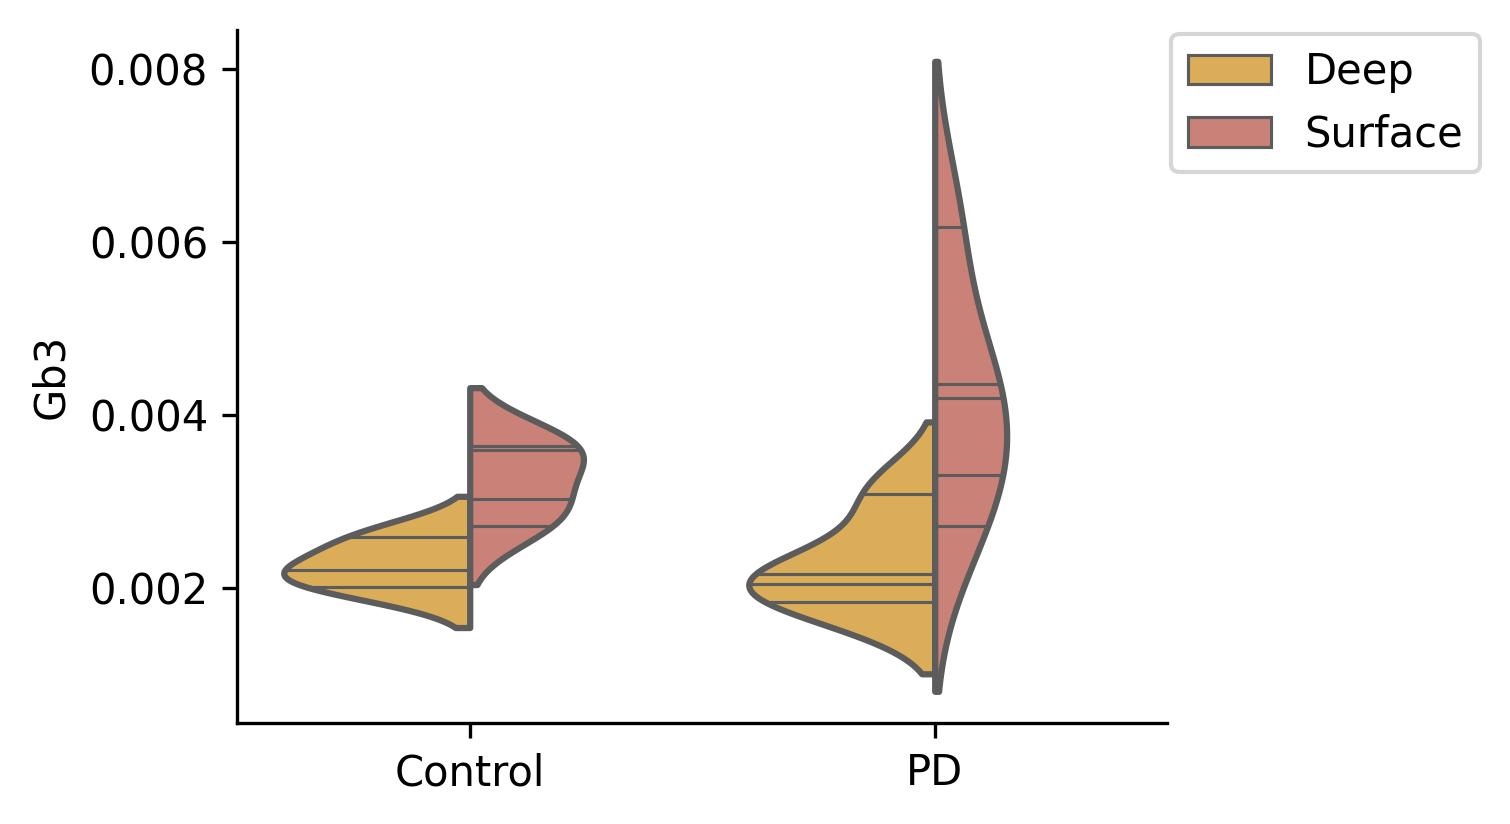

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

for cat in list(sig.index):
    sns.violinplot(x = df["group"], y = df[cat], hue = df["type"])
    sns.swarmplot(x = df["group"], y = df[cat], hue = df["type"])
    plt.show()

In [ ]:
df = pd.read_csv('RE_ Surface_Deep cortex (Zane) and ACG_IPL (Hardy) GSL and GlcCer analyses/Deep-surface/Deep-surface_all_comparisons.csv')
df['patient_id'] = list(df['id'].str.split('_', expand = True)[1].str.split('Deep', expand = True)[0].str.split('Surface', expand = True)[0])
df['type'] = np.where(df['id'].str.contains('Deep', case=False, na=False), 'Deep', 'Surface')
df.columns

['id',
 'group',
 'X2.16',
 'X2.16_nm_mL',
 'X2.67',
 'X2.67_nm_mL',
 'X3.23',
 'X3.23_nm_mL',
 'X3.57',
 'X3.57_nm_mL',
 'X3.61',
 'X3.61_nm_mL',
 'X4.03',
 'X4.03_nm_mL',
 'X5.24',
 'X5.24_nm_mL',
 'X5.33',
 'X5.33_nm_mL',
 'X5.45',
 'X5.45_nm_mL',
 'X5.99',
 'X5.99_nm_mL',
 'X6.84',
 'X6.84_nm_mL',
 'X6.99',
 'X6.99_nm_mL',
 'X8.07',
 'X8.07_nm_mL',
 'A_series',
 'A_series_nm_mL',
 'B_series',
 'B_series_nm_mL',
 'Charged',
 'Charged_neutral_ratio',
 'Charged_neutral_ratio_nm_mL',
 'Charged_nm_mL',
 'Charged_to_total_GSL',
 'Charged_to_total_GSL_nm_mL',
 'Column_1',
 'Column_1_nm_mL',
 'Column_2',
 'Column_2_nm_mL',
 'Column_3',
 'Column_3_nm_mL',
 'Column_4',
 'Column_4_nm_mL',
 'Di_sialyl_GSLs',
 'Di_sialyl_GSLs_nm_mL',
 'Di_to_Mono_ratio',
 'Di_to_Mono_ratio_nm_mL',
 'GA1',
 'GA1_nm_mL',
 'GA2',
 'GA2_nm_mL',
 'Gangliosides_o_a_b',
 'Gangliosides_o_a_b_nm_mL',
 'Gangliosides_o_a_b_to_total_GSL',
 'Gangliosides_o_a_b_to_total_GSL_nm_mL',
 'Gb3',
 'Gb3_nm_mL',
 'GD1a',
 'GD1a_nm_mL

c:\Users\melis\AppData\Local\Programs\Python\Python37\lib\site-packages\pandas\core\frame.py:5047: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  errors=errors,
c:\Users\melis\AppData\Local\Programs\Python\Python37\lib\site-packages\pandas\core\frame.py:4913: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  errors=errors,
c:\Users\melis\AppData\Local\Programs\Python\Python37\lib\site-packages\pandas\util\_decorators.py:311: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#re

X2.16
4
Calculated! 4
X2.16_nm_mL
4
Calculated! 4
X2.67
2
Skipping X2.67: only 2 samples
X2.67_nm_mL
2
Skipping X2.67_nm_mL: only 2 samples
X3.23
0
Skipping X3.23: only 0 samples
X3.23_nm_mL
0
Skipping X3.23_nm_mL: only 0 samples
X3.57
1
Skipping X3.57: only 1 samples
X3.57_nm_mL
1
Skipping X3.57_nm_mL: only 1 samples
X3.61
1
Skipping X3.61: only 1 samples
X3.61_nm_mL
1
Skipping X3.61_nm_mL: only 1 samples
X4.03
1
Skipping X4.03: only 1 samples
X4.03_nm_mL
1
Skipping X4.03_nm_mL: only 1 samples
X5.24
5
Calculated! 5
X5.24_nm_mL
5
Calculated! 5
X5.33
1
Skipping X5.33: only 1 samples
X5.33_nm_mL
1
Skipping X5.33_nm_mL: only 1 samples
X5.45
5
Calculated! 5
X5.45_nm_mL
5
Calculated! 5
X5.99
5
Calculated! 5
X5.99_nm_mL
5
Calculated! 5
X6.84
5
Calculated! 5
X6.84_nm_mL
5
Calculated! 5
X6.99
5
Calculated! 5
X6.99_nm_mL
5
Calculated! 5
X8.07
0
Skipping X8.07: only 0 samples
X8.07_nm_mL
0
Skipping X8.07_nm_mL: only 0 samples
A_series
5
Calculated! 5
A_series_nm_mL
5
Calculated! 5
B_series
5
Cal

In [231]:
sig

,statistic,pval,padj
X2.16,3.960549,0.028744,0.042899
X5.24,5.416247,0.005631,0.010624
X5.45,8.172066,0.001221,0.003219
X5.99,15.477038,0.000102,0.000437
X6.84,6.113425,0.003625,0.007794
...,...,...,...
total_area_per_condition,26.769597,0.000012,0.000103
Total_GSL_2_13_4_43,28.088153,0.000010,0.000092
Total_GSL_2_13_4_43_nm_mL,-22.416670,0.000023,0.000160
Total_GSL_4_61_7_18,19.511078,0.000041,0.000215


In [ ]:
sig.to_csv('all_comparisons.csv')

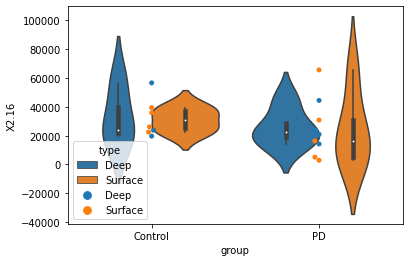

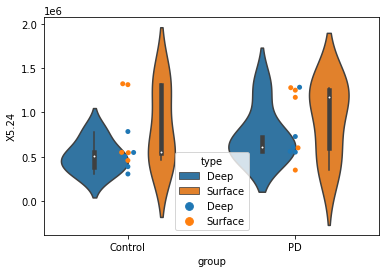

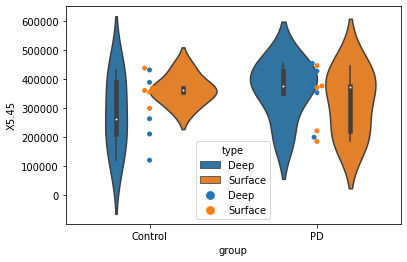

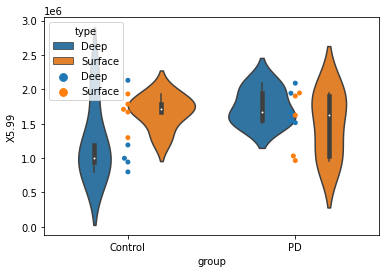

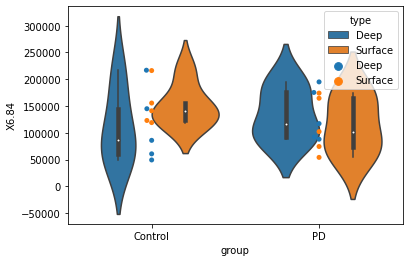

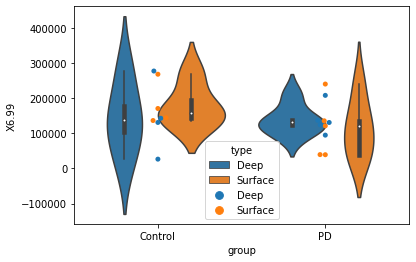

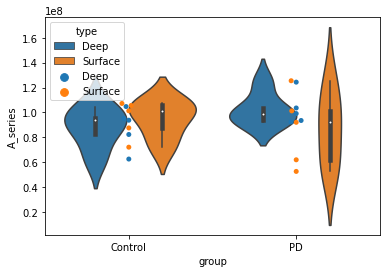

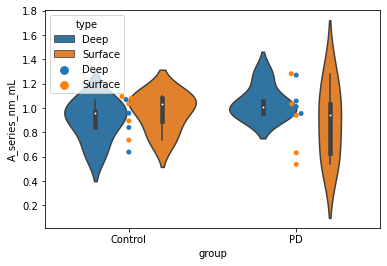

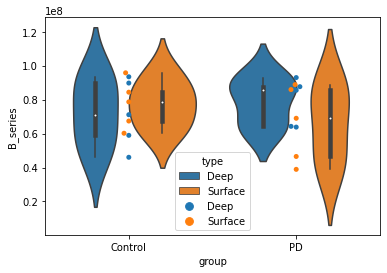

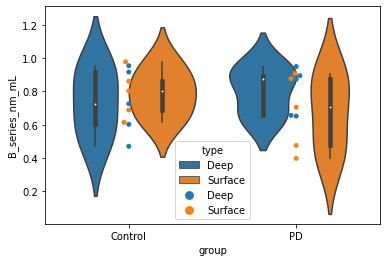

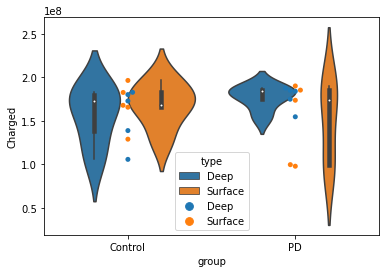

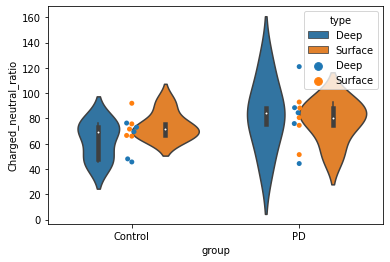

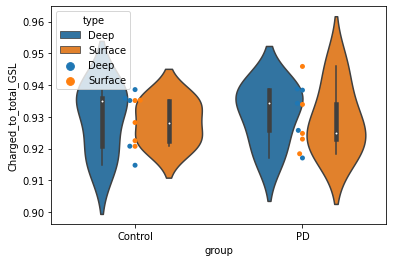

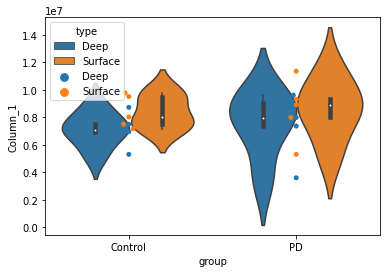

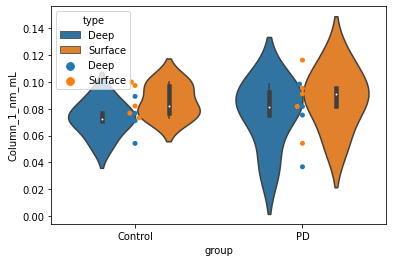

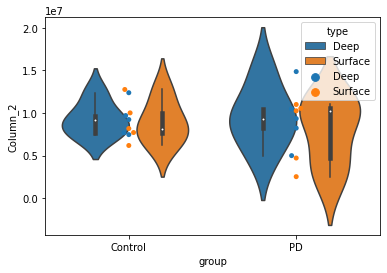

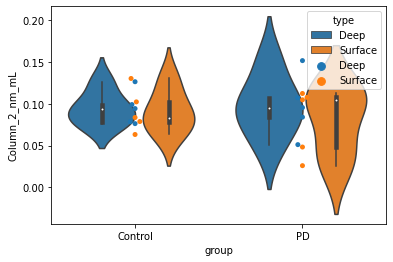

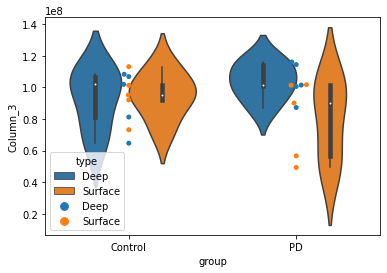

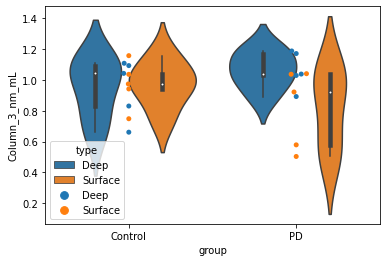

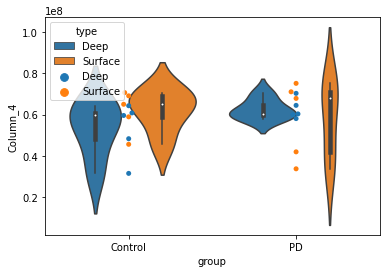

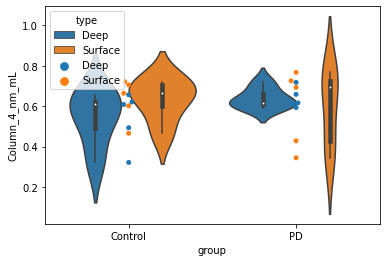

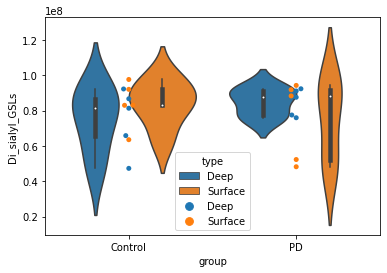

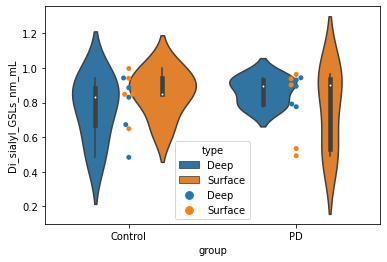

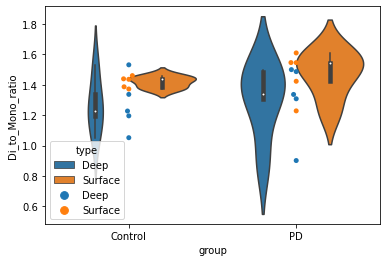

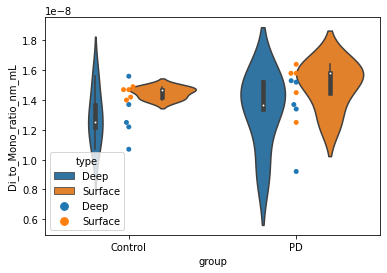

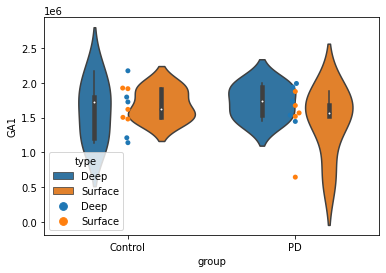

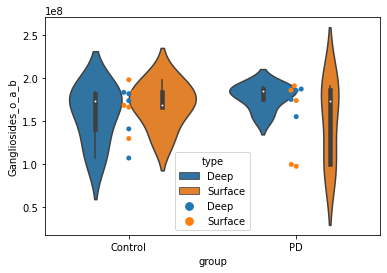

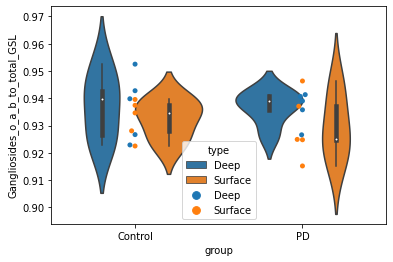

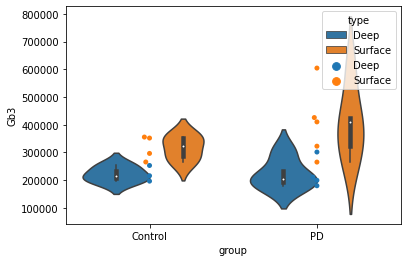

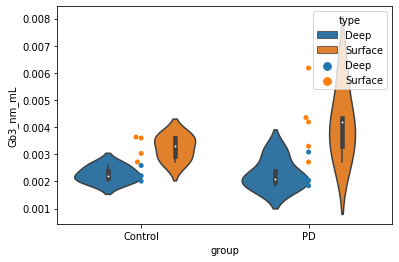

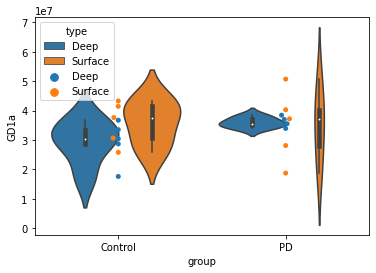

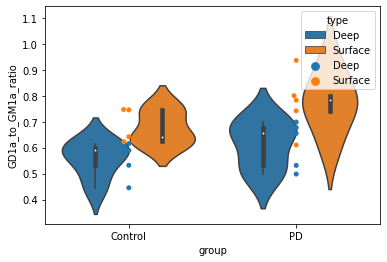

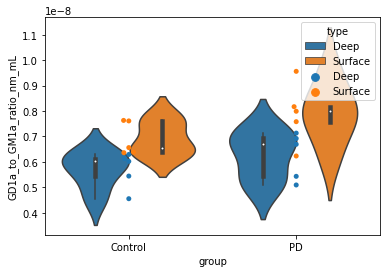

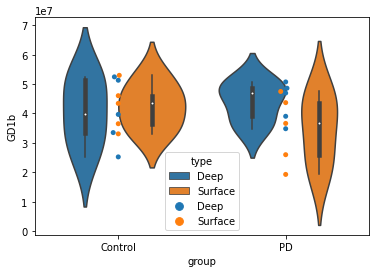

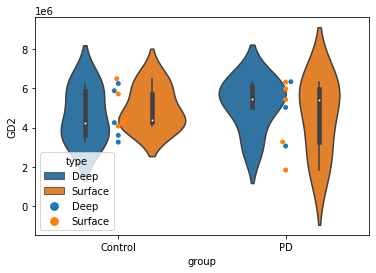

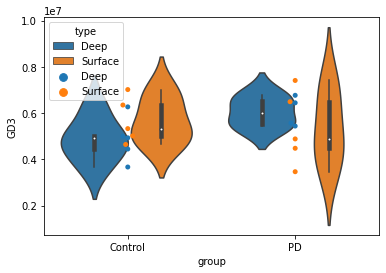

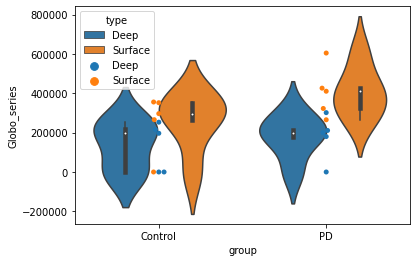

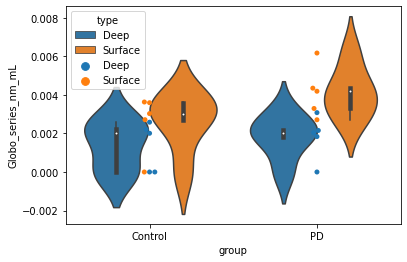

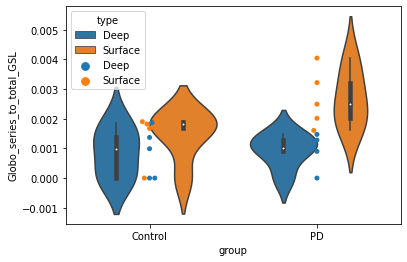

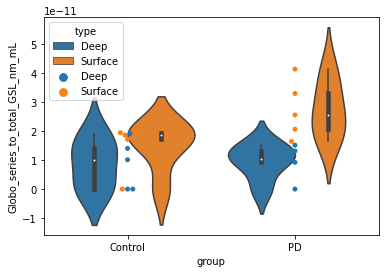

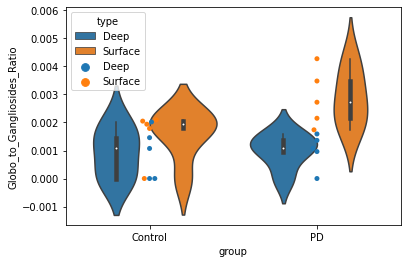

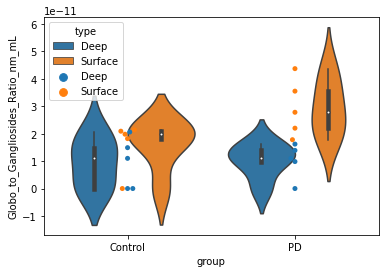

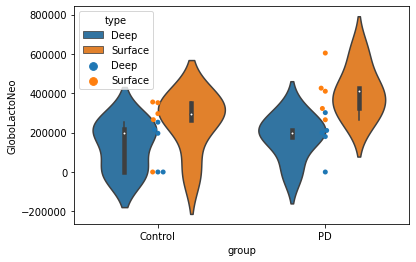

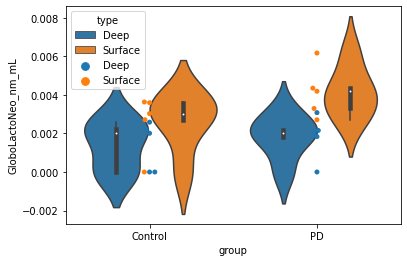

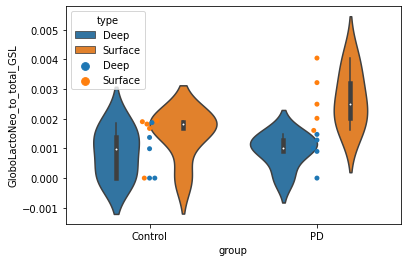

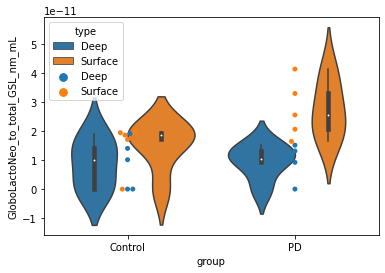

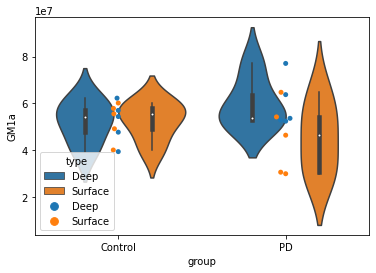

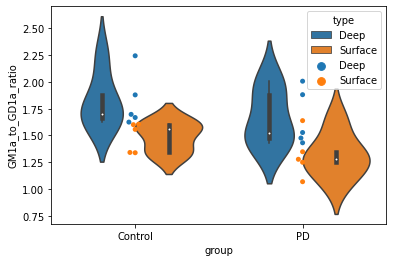

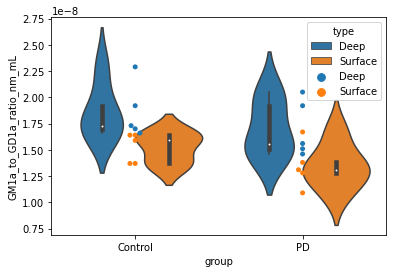

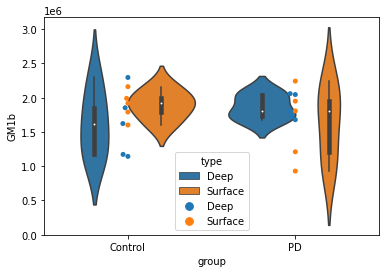

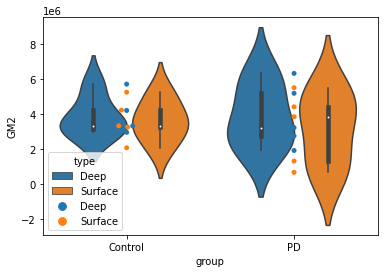

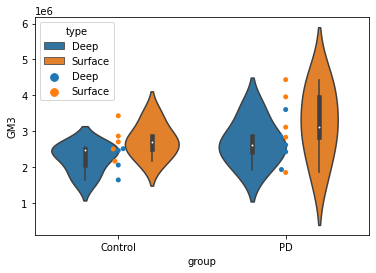

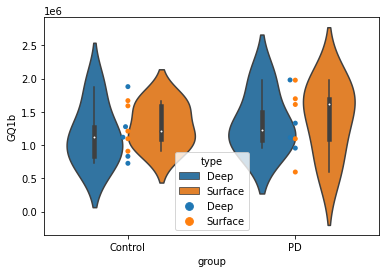

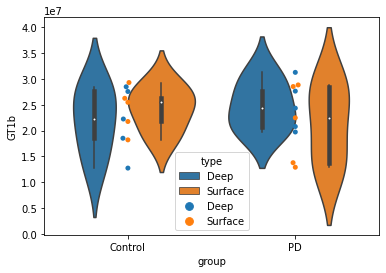

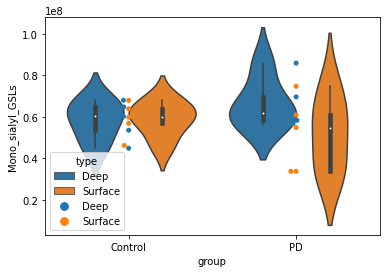

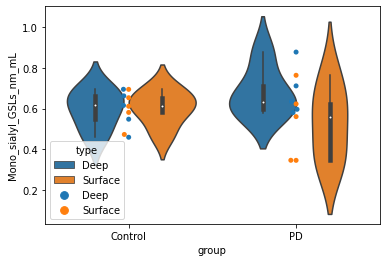

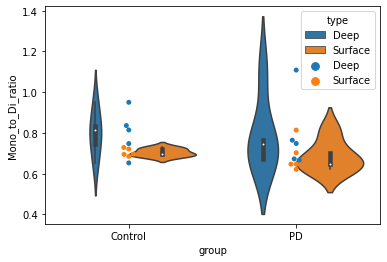

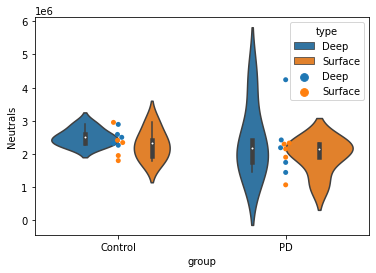

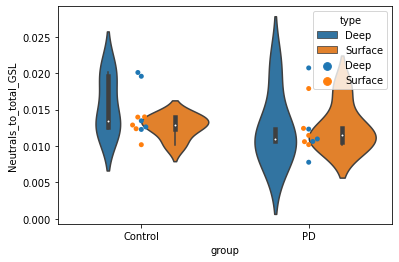

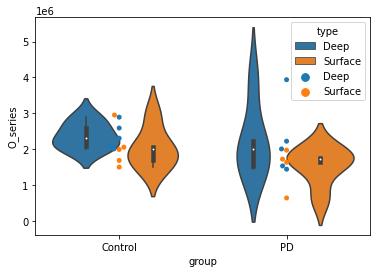

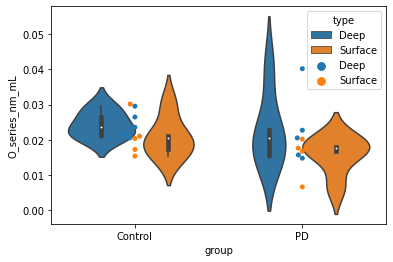

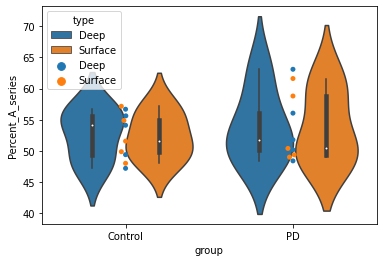

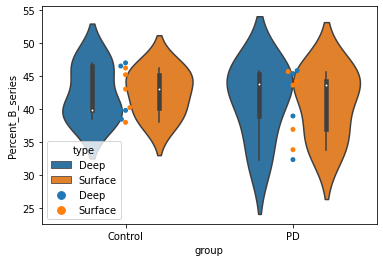

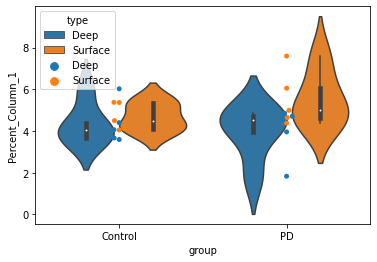

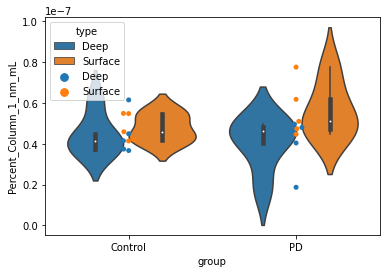

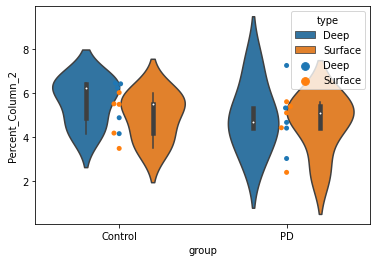

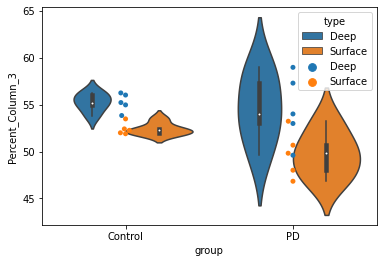

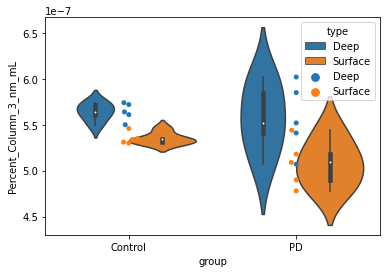

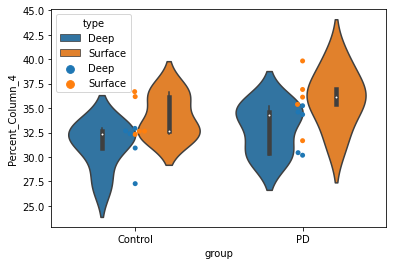

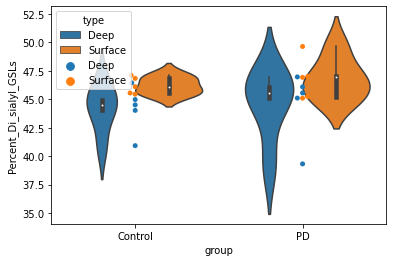

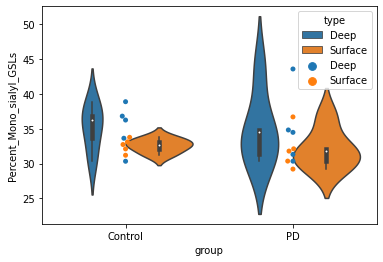

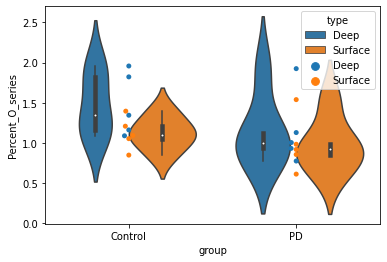

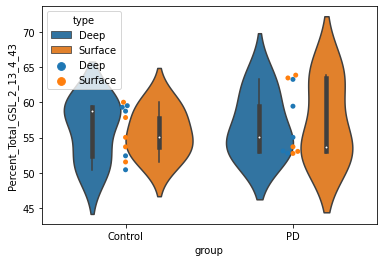

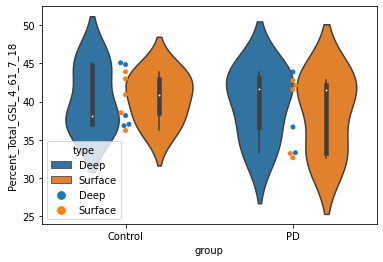

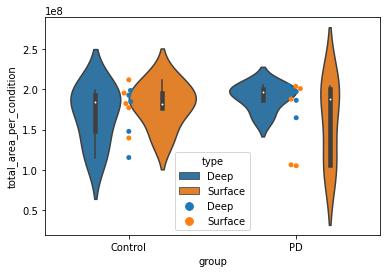

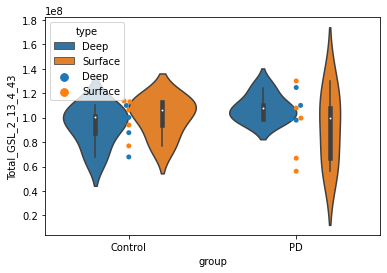

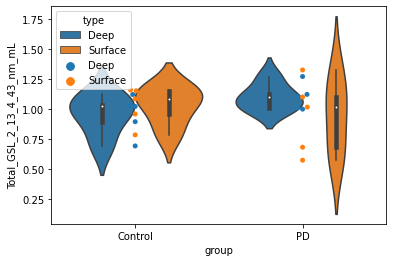

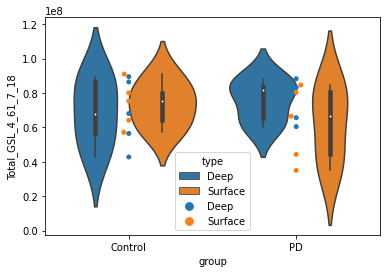

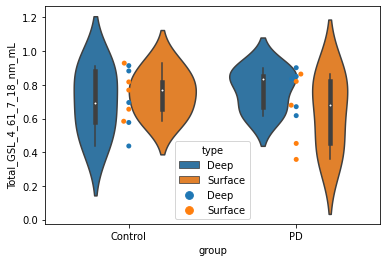

In [232]:
import seaborn as sns
import matplotlib.pyplot as plt

for cat in list(sig.index):
    sns.violinplot(x = df["group"], y = df[cat], hue = df["type"])
    sns.swarmplot(x = df["group"], y = df[cat], hue = df["type"])
    plt.show()

In [122]:
df = pd.read_csv('RE_ Surface_Deep cortex (Zane) and ACG_IPL (Hardy) GSL and GlcCer analyses/Deep-surface/Deep-surface_GSLs.csv')
df['patient_id'] = list(df['id'].str.split('_', expand = True)[1].str.split('Deep', expand = True)[0].str.split('Surface', expand = True)[0])
df['type'] = np.where(df['id'].str.contains('Deep', case=False, na=False), 'Deep', 'Surface')
categories = ['2.16', 'GA2', '2.67', 'Gb3', 'GM3', '3.23', 'GM2','3.57', '3.61', 'GA1', '4.03', 'GM1a', 'GD3', 'GM1b', 'GD2', 'GD1a','5.24', '5.33', '5.45', 'GD1b', '5.99', 'GT1b', '6.84', '6.99', 'GQ1b','8.07']

deep = df[df['type']=='Deep']
deep.columns = [col + '_deep' for col in deep.columns]
deep.rename(columns = {'id_deep':'id','group_deep':'group','patient_id_deep':'patient_id','type_deep':'type'}, inplace = True)

surface = df[df['type']=='Surface']
surface.columns = [col + '_surface' for col in surface.columns]
surface.drop(columns = ['group_surface', 'id_surface', 'type_surface', 'id_surface'], inplace = True)
surface.rename(columns = {'patient_id_surface':'patient_id'}, inplace = True)
surface

paired = deep.merge(surface, left_on = 'patient_id', right_on = 'patient_id', how = 'inner')

for comp in categories:
    paired_filtered = paired[[col for col in paired.columns if comp in col]]
    paired_filtered.dropna(inplace = True)
    print(comp)
    print(np.shape(paired_filtered))
    #res = stats.ttest_rel(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
    res = wilcoxon(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])


    if comp == '2.16':
        total_res = pd.DataFrame(res).T
    else:
        total_res = pd.concat([total_res, pd.DataFrame(res).T], axis = 0)


total_res.rename(columns = {0:'statistic',1:'pval'}, inplace = True)
total_res.index = categories
total_res.dropna(inplace = True)
total_res['padj'] = sm.fdrcorrection(list(total_res['pval']), alpha=0.05, method='indep', is_sorted=False)[1]

sig = total_res[total_res['pval']<0.05]

2.16
(6, 2)
GA2
(8, 2)
2.67
(3, 2)
Gb3
(6, 2)
GM3
(10, 2)
3.23
(1, 2)
GM2
(10, 2)
3.57
(2, 2)
3.61
(2, 2)
GA1
(10, 2)
4.03
(2, 2)
GM1a
(10, 2)
GD3
(9, 2)
GM1b
(10, 2)
GD2
(10, 2)
GD1a
(10, 2)
5.24
(10, 2)
5.33
(4, 2)
5.45
(10, 2)
GD1b
(10, 2)
5.99
(10, 2)
GT1b
(10, 2)
6.84
(10, 2)
6.99
(8, 2)
GQ1b
(9, 2)
8.07
(1, 2)


c:\Users\melis\AppData\Local\Programs\Python\Python37\lib\site-packages\pandas\core\frame.py:5047: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  errors=errors,
c:\Users\melis\AppData\Local\Programs\Python\Python37\lib\site-packages\pandas\core\frame.py:4913: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  errors=errors,
c:\Users\melis\AppData\Local\Programs\Python\Python37\lib\site-packages\pandas\util\_decorators.py:311: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#re

In [167]:
total_res[total_res['padj']<0.05]

,statistic,pval,padj
X2.16,0.0,0.031250,0.044118
X5.24,0.0,0.001953,0.003780
X5.45,0.0,0.001953,0.003780
X5.99,0.0,0.001953,0.003780
X6.84,0.0,0.001953,0.003780
...,...,...,...
total_area_per_condition,0.0,0.001953,0.003780
Total_GSL_2_13_4_43,0.0,0.001953,0.003780
Total_GSL_2_13_4_43_nm_mL,0.0,0.001953,0.003780
Total_GSL_4_61_7_18,0.0,0.001953,0.003780
